In [51]:
import numpy as np
import pandas as pd
import pandas_ta as ta
import matplotlib.pyplot as plt
import yfinance as yf
import mplfinance as mpf
import requests
import plotly.graph_objects as go
from plotly.subplots import make_subplots

## Functions Definitions

In [52]:
def get_tsla_recent_data():
    session = requests.Session()
    session.headers.update({'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/58.0.3029.110 Safari/537.3'})
    tsla = yf.Ticker('TSLA')
    df = tsla.history(period='4mo', interval='4h')
    return df

def visualize_interactive(df, title="TSLA Candlestick Chart"):
    fig = go.Figure()
    
    # Add candlestick chart
    fig.add_trace(go.Candlestick(
        x=df.index,
        open=df['Open'],
        high=df['High'],
        low=df['Low'],
        close=df['Close'],
        name='TSLA'
    ))
    
    # Add SMA 50 line
    fig.add_trace(go.Scatter(
        x=df.index,
        y=df['SMA_short'],
        mode='lines',
        name='SMA Short(10)',
        line=dict(color='blue', width=2)
    ))
    
    # Add SMA 200 line
    fig.add_trace(go.Scatter(
        x=df.index,
        y=df['SMA_long'],
        mode='lines',
        name='SMA Long(20)',
        line=dict(color='orange', width=2)
    ))
    
    fig.update_layout(title=title, xaxis_rangeslider_visible=False)
    fig.show()

def visualize_interactive_with_rsi(df, title="TSLA Candlestick Chart with RSI"):
    # Create subplots: 2 rows, 1 column
    # Row 1: Candlestick + Moving Averages
    # Row 2: RSI
    fig = make_subplots(
        rows=2, cols=1,
        shared_xaxes=True,
        vertical_spacing=0.1,
        subplot_titles=('TSLA Price with Moving Averages', 'RSI (14)'),
        row_width=[0.7, 0.3]  # Price chart takes 70%, RSI takes 30%
    )
    
    # Add candlestick chart to first subplot
    fig.add_trace(go.Candlestick(
        x=df.index,
        open=df['Open'],
        high=df['High'],
        low=df['Low'],
        close=df['Close'],
        name='TSLA'
    ), row=1, col=1)
    
    # Add EMA 10 line
    fig.add_trace(go.Scatter(
        x=df.index,
        y=df['EMA_10'],
        mode='lines',
        name='EMA 10',
        line=dict(color='blue', width=2)
    ), row=1, col=1)
    
    # Add EMA 20 line
    fig.add_trace(go.Scatter(
        x=df.index,
        y=df['EMA_20'],
        mode='lines',
        name='EMA 20',
        line=dict(color='orange', width=2)
    ), row=1, col=1)
    
    # Add RSI to second subplot
    fig.add_trace(go.Scatter(
        x=df.index,
        y=df['RSI'],
        mode='lines',
        name='RSI',
        line=dict(color='purple', width=2)
    ), row=2, col=1)
    
    # Add RSI reference lines
    fig.add_hline(y=70, line_dash="dash", line_color="red", 
                  annotation_text="Overbought (70)", row=2, col=1)
    fig.add_hline(y=30, line_dash="dash", line_color="green", 
                  annotation_text="Oversold (30)", row=2, col=1)
    fig.add_hline(y=50, line_dash="dot", line_color="gray", 
                  annotation_text="Midline (50)", row=2, col=1)
    
    # Update layout
    fig.update_layout(
        title=title,
        xaxis_rangeslider_visible=False,
        height=800,
        showlegend=True
    )
    
    # Update y-axis for RSI
    fig.update_yaxes(title_text="Price", row=1, col=1)
    fig.update_yaxes(title_text="RSI", range=[0, 100], row=2, col=1)
    fig.update_xaxes(title_text="Date", row=2, col=1)
    
    fig.show()


def calculate_signals(df):
    """Calculate buy/sell signals based on RSI + EMA strategy"""
    df['Signal'] = 0
    df['Signal_Type'] = ''
    
    # Calculate EMA crossovers
    df['EMA_Cross'] = 0
    df['EMA_Cross'] = (df['EMA_10'] > df['EMA_20']).astype(int) * 2 - 1  # 1 for bullish, -1 for bearish
    df['EMA_Cross_Signal'] = df['EMA_Cross'].diff()
    
    for i in range(1, len(df)):
        # Bullish signal: EMA10 crosses above EMA20 AND RSI confirms
        if (df['EMA_Cross_Signal'].iloc[i] == 2 and  # EMA bullish cross
            df['RSI'].iloc[i] > 50 and  # RSI above midline
            df['RSI'].iloc[i] > df['RSI'].iloc[i-1]):  # RSI rising
            
            df.loc[df.index[i], 'Signal'] = 1
            df.loc[df.index[i], 'Signal_Type'] = 'BUY'
        
        # Bearish signal: EMA10 crosses below EMA20 AND RSI confirms  
        elif (df['EMA_Cross_Signal'].iloc[i] == -2 and  # EMA bearish cross
              df['RSI'].iloc[i] < 50 and  # RSI below midline
              df['RSI'].iloc[i] < df['RSI'].iloc[i-1]):  # RSI falling
            
            df.loc[df.index[i], 'Signal'] = -1
            df.loc[df.index[i], 'Signal_Type'] = 'SELL'
    
    return df

def visualize_with_signals(df, title="TSLA Strategy with Buy/Sell Signals"):
    """Enhanced visualization with buy/sell signals"""
    fig = make_subplots(
        rows=2, cols=1,
        shared_xaxes=True,
        vertical_spacing=0.1,
        subplot_titles=('TSLA Price with Signals', 'RSI (14)'),
        row_width=[0.7, 0.3]
    )
    
    # Add candlestick chart
    fig.add_trace(go.Candlestick(
        x=df.index,
        open=df['Open'],
        high=df['High'],
        low=df['Low'],
        close=df['Close'],
        name='TSLA'
    ), row=1, col=1)
    
    # Add EMAs
    fig.add_trace(go.Scatter(
        x=df.index, y=df['EMA_10'],
        mode='lines', name='EMA 10',
        line=dict(color='blue', width=2)
    ), row=1, col=1)
    
    fig.add_trace(go.Scatter(
        x=df.index, y=df['EMA_20'],
        mode='lines', name='EMA 20',
        line=dict(color='orange', width=2)
    ), row=1, col=1)
    
    # Add buy signals
    buy_signals = df[df['Signal'] == 1]
    if not buy_signals.empty:
        fig.add_trace(go.Scatter(
            x=buy_signals.index,
            y=buy_signals['Close'],
            mode='markers',
            marker=dict(symbol='triangle-up', size=15, color='green'),
            name='BUY Signal'
        ), row=1, col=1)
    
    # Add sell signals
    sell_signals = df[df['Signal'] == -1]
    if not sell_signals.empty:
        fig.add_trace(go.Scatter(
            x=sell_signals.index,
            y=sell_signals['Close'],
            mode='markers',
            marker=dict(symbol='triangle-down', size=15, color='red'),
            name='SELL Signal'
        ), row=1, col=1)
    
    # Add RSI
    fig.add_trace(go.Scatter(
        x=df.index, y=df['RSI'],
        mode='lines', name='RSI',
        line=dict(color='purple', width=2)
    ), row=2, col=1)
    
    # RSI reference lines
    fig.add_hline(y=70, line_dash="dash", line_color="red", row=2, col=1)
    fig.add_hline(y=30, line_dash="dash", line_color="green", row=2, col=1)
    fig.add_hline(y=50, line_dash="dot", line_color="gray", row=2, col=1)
    
    # Update layout
    fig.update_layout(
        title=title,
        xaxis_rangeslider_visible=False,
        height=800,
        showlegend=True
    )
    
    fig.update_yaxes(title_text="Price", row=1, col=1)
    fig.update_yaxes(title_text="RSI", range=[0, 100], row=2, col=1)
    fig.update_xaxes(title_text="Date", row=2, col=1)
    
    fig.show()

In [53]:
df = get_tsla_recent_data()
df['EMA_10'] = ta.ema(df['Close'], length=10)  # Fixed naming
df['EMA_20'] = ta.ema(df['Close'], length=20)  # Fixed naming  
df['RSI'] = ta.rsi(df['Close'], length=14)

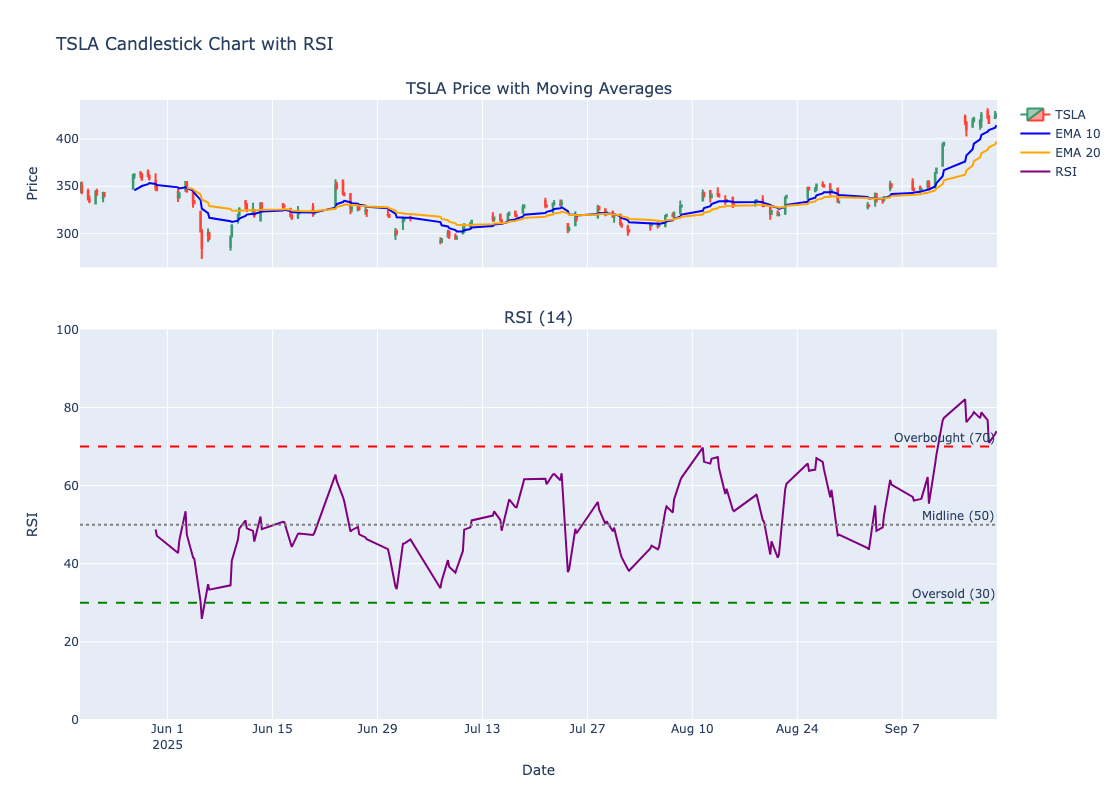

In [54]:
visualize_interactive_with_rsi(df)

In [55]:
df_signals = calculate_signals(df)

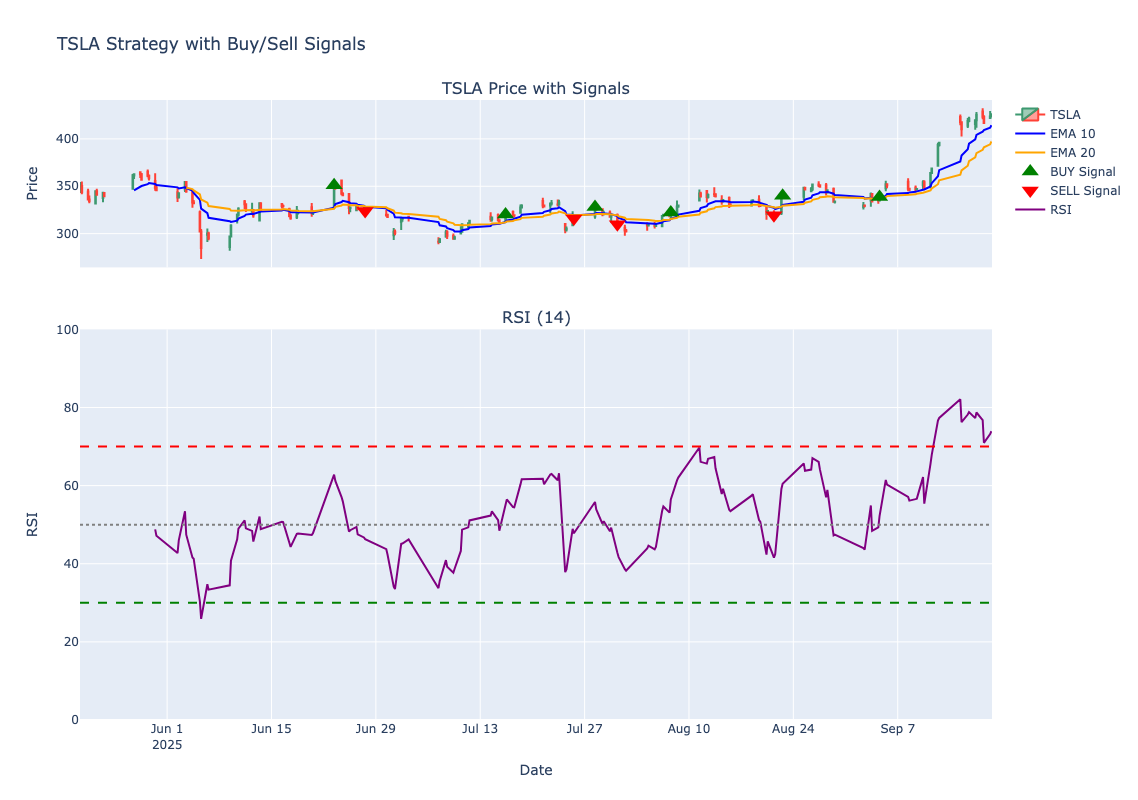

In [56]:
visualize_with_signals(df)